# EMQA_L5_collar

**Effective price of the Cal-27 band with forward, cap and collar**

Energy Markets Quantitative Analysis (EMQA), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L5/EMQA_L5_collar/EMQA_L5_collar.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

What each instrument pays for next year's band: inputs of the Black-76 model taken from real data.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5,
    'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
# fixed colour per entity (course palette)
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}


def legend_bottom(fig, handles=None, labels=None, ncol=4):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0),
               frameon=False, handlelength=2.0, columnspacing=1.2)


def show(label, value, key=None, fmt='.2f'):
    """Print one number of the slide; [key] = its name in lectures/L5/L5_numbers.json."""
    s = value if isinstance(value, str) else format(value, fmt)
    print(f'{label:<58s} {s:>12s}' + (f'   [{key}]' if key else ''))

In [3]:
# daily day-ahead base prices (mean of all market time units of the CET/CEST day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month of the Romanian series
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
d = lambda ts: pd.Timestamp(ts).strftime('%Y-%m-%d')
print('cut-off (last complete month):', d(END))

cut-off (last complete month): 2026-10-31


In [4]:
# OPCOM PCCB-LE-flex auction results: one row per traded session, price converted to EUR with the ECB EUR/RON fixing
FW = pd.read_csv(DATA + 'opcom_forward_trades.csv', parse_dates=['auction_date', 'delivery_start', 'delivery_end'])
FW = FW[FW['auction_date'] <= END].copy()


def kind_of(s, e):
    """Standard delivery period of a product: M (month), Q (quarter), H (half-year), Y (calendar year), else 'other'."""
    if s.day != 1 or (e + pd.Timedelta(days=1)).day != 1:
        return 'other'
    n = (e.year - s.year) * 12 + e.month - s.month + 1
    if n == 1:
        return 'M'
    if n == 3 and s.month in (1, 4, 7, 10):
        return 'Q'
    if n == 6 and s.month in (1, 7):
        return 'H'
    if n == 12 and s.month == 1:
        return 'Y'
    return 'other'


FW['kind'] = [kind_of(s, e) for s, e in zip(FW['delivery_start'], FW['delivery_end'])]
FW['lead_m'] = ((FW['delivery_start'].dt.year - FW['auction_date'].dt.year) * 12 +
                FW['delivery_start'].dt.month - FW['auction_date'].dt.month)
# baseload ('banda LD') products with a standard delivery period
BASE = FW[(FW['profile'] == 'banda LD') & (FW['kind'] != 'other')].copy()


def vwap(df):
    """Volume-weighted average price, EUR/MWh."""
    return float(np.average(df['price_eur_mwh'], weights=df['mwh'])) if len(df) else np.nan


def realised(s, e, col='RO'):
    """Mean day-ahead base price over [s, e] (CET days); NaN unless every day is present."""
    x = PD.loc[s:e, col]
    full = len(x) == (e - s).days + 1 and x.notna().all()
    return float(x.mean()) if full else np.nan


print(len(FW), 'traded auctions from', d(FW['auction_date'].min()), 'to', d(FW['auction_date'].max()),
      '|', len(BASE), 'baseload auctions with a standard delivery period')

2298 traded auctions from 2020-05-12 to 2026-10-28 | 1361 baseload auctions with a standard delivery period


In [5]:
# calendar-year baseload products
CY = BASE[BASE['kind'] == 'Y'].copy()
CY['dy'] = CY['delivery_start'].dt.year

In [6]:
# forward curve: baseload products traded in the last three months for delivery after the cut-off, VWAP per product
CURVE_FROM = (END - pd.DateOffset(months=2) + pd.Timedelta(days=1)).normalize()
cur = BASE[(BASE['auction_date'] >= CURVE_FROM) & (BASE['delivery_start'] > END)]
curve = (cur.groupby(['delivery_start', 'delivery_end', 'kind'])
         .apply(lambda g: pd.Series({'F': vwap(g), 'n': len(g), 'twh': g['mwh'].sum() / 1e6})).reset_index())

In [7]:
from scipy.stats import norm


def black76(F, K, T, r, sigma, kind='call'):
    """Black (1976) price of a European option on a forward F; returns price, delta, vega (per 1 vol point), d1, d2."""
    d1 = (np.log(F / K) + 0.5 * sigma ** 2 * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    disc = np.exp(-r * T)
    if kind == 'call':
        p, delta = disc * (F * norm.cdf(d1) - K * norm.cdf(d2)), disc * norm.cdf(d1)
    else:
        p, delta = disc * (K * norm.cdf(-d2) - F * norm.cdf(-d1)), -disc * norm.cdf(-d1)
    vega = disc * F * norm.pdf(d1) * np.sqrt(T) / 100
    return float(p), float(delta), float(vega), float(d1), float(d2)


# euro short-term rate (ECB)
RATES = pd.read_csv(DATA + 'ecb_ron_estr_daily.csv', parse_dates=['date']).set_index('date')

In [8]:
def cal_vol(g, max_gap=30):
    """Volatility of a calendar forward from irregular auction days: daily VWAP, sigma^2 = sum (d ln F)^2 / sum dt,
    using only pairs of auction days at most max_gap calendar days apart."""
    dv = g.groupby('auction_date').apply(vwap)
    dl = np.log(dv).diff().dropna()
    dt = dv.index.to_series().diff().dt.days.dropna() / 365.25
    m = dt <= max_gap / 365.25
    return dl[m], dt[m]


DL, DT = [], []
for y in [END.year - 1, END.year, END.year + 1]:
    dl, dt = cal_vol(CY[CY['dy'] == y])
    DL.append(dl)
    DT.append(dt)
sig = float(np.sqrt(sum((x ** 2).sum() for x in DL) / sum(x.sum() for x in DT)))   # pooled volatility

cal = curve[curve['kind'] == 'Y'].sort_values('delivery_start')
F0 = round(float(cal['F'].iloc[0]), 2)                     # next calendar year on the curve (VWAP)
R = RATES['estr_pct'].loc[:END].dropna()
r0 = R.iloc[-1] / 100
EXPIRY = pd.Timestamp(f'{END.year}-12-15')
T0 = (EXPIRY - END).days / 365.25
c110, _, _, _, _ = black76(F0, 1.1 * F0, T0, r0, sig, 'call')
p90, _, _, _, _ = black76(F0, 0.9 * F0, T0, r0, sig, 'put')
c_atm, _, _, _, _ = black76(F0, F0, T0, r0, sig, 'call')
show(f"F = Cal-{cal['delivery_start'].iloc[0].year} baseload VWAP, EUR/MWh", F0, 'bs.F', '.2f')
show('volatility of the calendar forwards (pooled), per year', sig, 'bs.sig_cal', '.4f')
show(f'euro short-term rate on {d(R.index[-1])}, %', r0 * 100, 'bs.r', '.3f')
show(f'time to expiry ({d(EXPIRY)}), years', T0, 'bs.T', '.4f')
show('at-the-money call, EUR/MWh', c_atm, 'bs.c.call', '.2f')
show('cap strike K = 1.1 F, EUR/MWh', 1.1 * F0, 'bs.K110', '.2f')
show('floor strike 0.9 F, EUR/MWh', 0.9 * F0, 'bs.K90', '.2f')
show('call at 1.1 F, EUR/MWh', c110, 'bs.c.call110', '.2f')
show('put at 0.9 F, EUR/MWh', p90, 'bs.c.put90', '.2f')
show('collar = call 1.1 F - put 0.9 F, EUR/MWh', c110 - p90, 'bs.c.collar', '.2f')
show('cap premium per MW of baseload for a year, EUR', round(c110, 2) * 8760, 'bs.mw_year', ',.0f')   # premium as quoted (2 decimals) x 8760 h

F = Cal-2027 baseload VWAP, EUR/MWh                              148.12   [bs.F]
volatility of the calendar forwards (pooled), per year           0.2202   [bs.sig_cal]
euro short-term rate on 2026-10-30, %                             2.440   [bs.r]
time to expiry (2026-12-15), years                               0.1232   [bs.T]
at-the-money call, EUR/MWh                                         4.55   [bs.c.call]
cap strike K = 1.1 F, EUR/MWh                                    162.93   [bs.K110]
floor strike 0.9 F, EUR/MWh                                      133.31   [bs.K90]
call at 1.1 F, EUR/MWh                                             0.63   [bs.c.call110]
put at 0.9 F, EUR/MWh                                              0.43   [bs.c.put90]
collar = call 1.1 F - put 0.9 F, EUR/MWh                           0.20   [bs.c.collar]
cap premium per MW of baseload for a year, EUR                    5,519   [bs.mw_year]


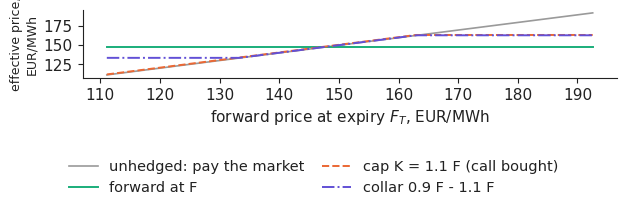

In [9]:
fig, ax = plt.subplots(figsize=(6.4, 2.15))
FT = np.linspace(0.75 * F0, 1.3 * F0, 200)                      # forward price at expiry
cT, pT = round(c110, 2) * np.exp(r0 * T0), round(p90, 2) * np.exp(r0 * T0)    # premia carried to expiry
ax.plot(FT, FT, color='#9a9a9a', lw=1.2, label='unhedged: pay the market')
ax.plot(FT, np.full_like(FT, F0), color=PAL['HU'], lw=1.4, label='forward at F')
ax.plot(FT, np.minimum(FT, 1.1 * F0) + cT, color=PAL['DE_LU'], lw=1.4, ls='--', label='cap K = 1.1 F (call bought)')
ax.plot(FT, np.clip(FT, 0.9 * F0, 1.1 * F0) + cT - pT, color=PAL['c7'], lw=1.4, ls='-.', label='collar 0.9 F - 1.1 F')
ax.set_xlabel('forward price at expiry $F_T$, EUR/MWh')
ax.set_ylabel('effective price,\nEUR/MWh', fontsize=9)
legend_bottom(fig, ncol=2)
fig.tight_layout(rect=(0, 0.3, 1, 1))
plt.savefig('collar.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()